In [13]:
import torch
import torch.nn as nn
# одна из крутейших букв
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

In [14]:
data1 = np.load('data/train-1.npy', allow_pickle=True)
data2 = np.load('data/train-2.npy', allow_pickle=True)
data3 = np.load('data/train-3.npy', allow_pickle=True)
data4 = np.load('data/train-4.npy', allow_pickle=True)
data1.shape, data2.shape, data3.shape, data4.shape

((83246, 2), (83247, 2), (83247, 2), (83247, 2))

In [15]:
data = np.concatenate([data1, data2, data3, data4])
data.shape

(332987, 2)

In [16]:
labels = data[:, 1]
n_classes = np.unique(labels).shape[0]
n_classes

1000

In [17]:
labels = pd.Series(labels, dtype='category')
labels.head()

0    59076
1    59076
2    59332
3    59844
4    60100
dtype: category
Categories (1000, int64): [58827, 58828, 58829, 58830, ..., 65235, 65236, 65237, 65238]

In [18]:
from sklearn.preprocessing import LabelEncoder

# Suppose `labels` is your full label list (strings or ints)
le = LabelEncoder()
labels_encoded = le.fit_transform(labels)
labels_encoded

array([ 33,  33,  73, ..., 130, 840, 968], shape=(332987,))

In [19]:
n_classes

1000

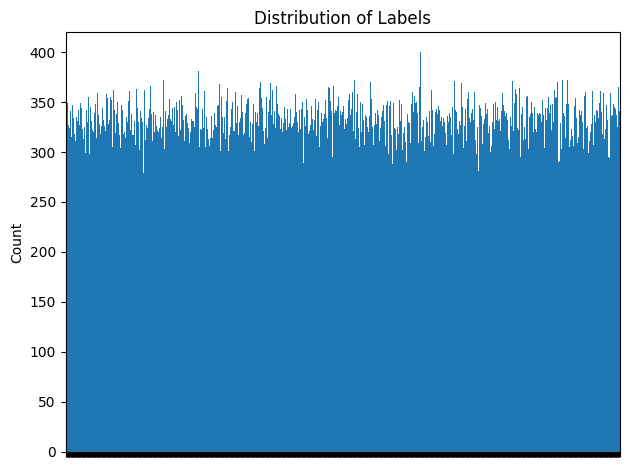

In [21]:
label_counts = pd.Series(labels).value_counts().sort_index()
ax = label_counts.plot(kind='bar', width=1.0)
ax.set_ylabel('Count')
ax.set_title('Distribution of Labels')
ax.set_xticklabels([])
plt.tight_layout()
plt.show()

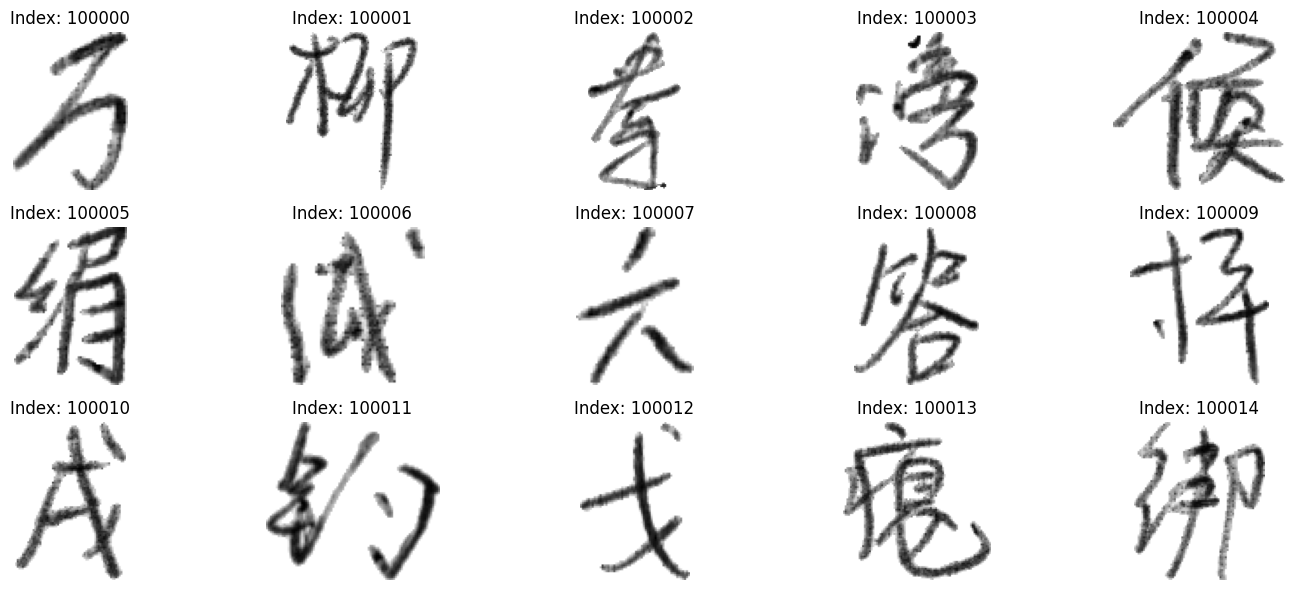

In [22]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 5, figsize=(15, 6))
for idx, ax in enumerate(axes.flat):
    img_idx = 100000 + idx
    ax.imshow(data[img_idx][0], cmap='gray')
    ax.axis("off")
    ax.set_title(f"Index: {img_idx}")
plt.tight_layout()
plt.show()

In [ ]:
from collections import Counter
import pandas as pd

shapes = [data[i][0].shape for i in range(len(data))]
shape_counts = Counter(shapes)
shapes = list(shape_counts.keys())
df_shapes = pd.DataFrame(shapes, columns=['Height', 'Width'])
df_shapes.describe()

,Height,Width
count,8092.000000,8092.000000
mean,88.395823,77.680919
std,28.178315,26.171275
min,8.000000,13.000000
25%,66.000000,57.000000
50%,88.000000,77.000000
75%,109.000000,98.000000
max,207.000000,164.000000


In [24]:
data.shape

(332987, 2)

In [25]:
images = data[:, 0]
images[0]

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], shape=(69, 72), dtype=uint8)

In [26]:
labels = data[:, 1]
labels = pd.DataFrame(labels, columns=['Label'])
labels.describe()

,Label
count,332987
unique,1000
top,62925
freq,400


In [30]:
labels.head()

,Label
0,59076
1,59076
2,59332
3,59844
4,60100


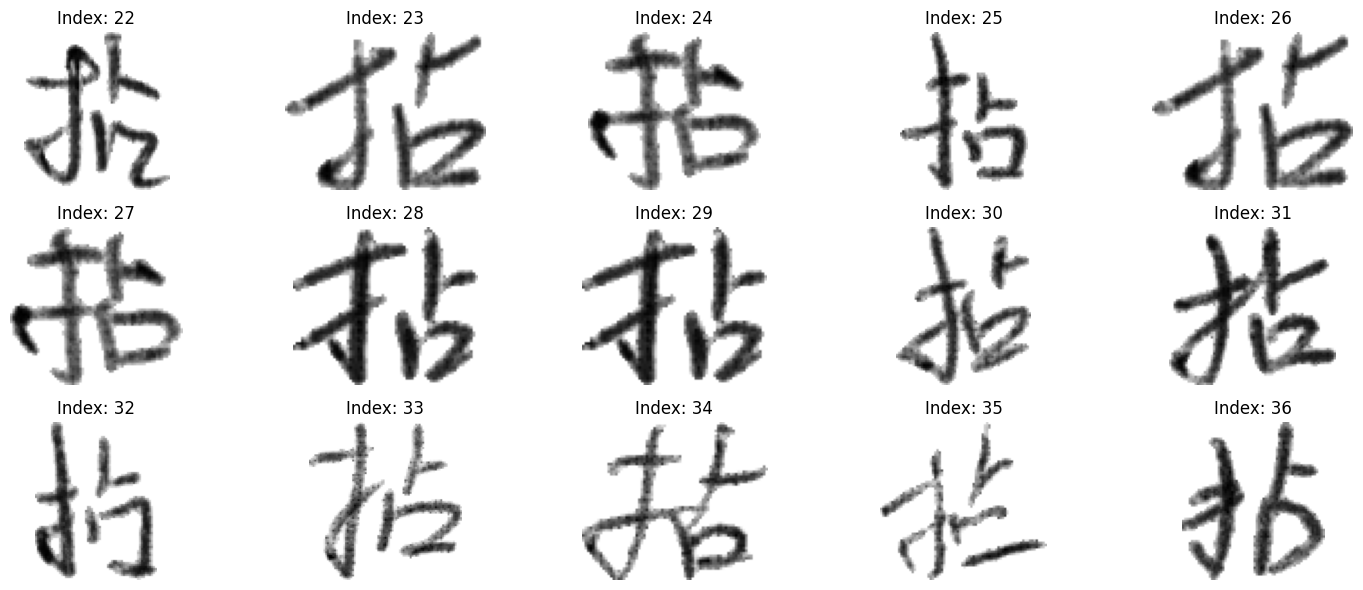

In [31]:
df_row = labels[labels['Label'] == 59844]

fig, axes = plt.subplots(3, 5, figsize=(15, 6))
offset = 22
for idx, ax in enumerate(axes.flat):
    index_at_images = df_row.index[offset + idx]
    ax.imshow(images[index_at_images], cmap='gray')
    ax.axis("off")
    ax.set_title(f"Index: {offset + idx}")
plt.tight_layout()
plt.show()


In [ ]:
%pip install opencv-python


[notice] A new release of pip is available: 25.0.1 -> 25.1.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
IMG_SIZE = 64
'''import cv2

def resize_and_pad(img, size=96):
    # Convert to numpy if not already
    img = np.array(img)
    
    h, w = img.shape[:2]
    scale = size / max(h, w)  # scaling factor to fit the largest dimension

    # Resize image with aspect ratio preserved
    new_h, new_w = int(h * scale), int(w * scale)
    resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)

    # Pad the image to be size x size
    pad_h = (size - new_h) // 2
    pad_w = (size - new_w) // 2
    padded = np.pad(resized, ((pad_h, size - new_h - pad_h), (pad_w, size - new_w - pad_w)), mode='constant', constant_values=255)

    return padded

to_test = data[123456:123456 + 15]  # Example test data
processed_images = [resize_and_pad(x[0], size=96) / 255.0 for x in to_test]  # Normalize to [0,1]
processed_images = np.array(processed_images).reshape(-1, 96, 96, 1)  # Add channel

fig, axes = plt.subplots(3, 5, figsize=(15, 6))
offset = 0
for idx, ax in enumerate(axes.flat):
    ax.imshow(processed_images[offset + idx], cmap='gray')
    ax.axis("off")
    ax.set_title(f"Index: {offset + idx}")
plt.tight_layout()
plt.show()'''

'import cv2\n\ndef resize_and_pad(img, size=96):\n    # Convert to numpy if not already\n    img = np.array(img)\n    \n    h, w = img.shape[:2]\n    scale = size / max(h, w)  # scaling factor to fit the largest dimension\n\n    # Resize image with aspect ratio preserved\n    new_h, new_w = int(h * scale), int(w * scale)\n    resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)\n\n    # Pad the image to be size x size\n    pad_h = (size - new_h) // 2\n    pad_w = (size - new_w) // 2\n    padded = np.pad(resized, ((pad_h, size - new_h - pad_h), (pad_w, size - new_w - pad_w)), mode=\'constant\', constant_values=255)\n\n    return padded\n\nto_test = data[123456:123456 + 15]  # Example test data\nprocessed_images = [resize_and_pad(x[0], size=96) / 255.0 for x in to_test]  # Normalize to [0,1]\nprocessed_images = np.array(processed_images).reshape(-1, 96, 96, 1)  # Add channel\n\nfig, axes = plt.subplots(3, 5, figsize=(15, 6))\noffset = 0\nfor idx, ax in enumerate(axes.f

In [ ]:
IMG_SIZE = 64
from torch.utils.data import TensorDataset, DataLoader

def get_chinese_data(batch_size, transform_train):
    torch.manual_seed(0)
    np.random.seed(0)

    transform_test = transforms.Compose([
        transforms.ToPILImage(),
        transforms.Resize((IMG_SIZE, IMG_SIZE)),        # критично
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)) # отрезок -1, 1 но на чб
    ])

    # Загружаем данные
    data1 = np.load('data/train-1.npy', allow_pickle=True)
    data2 = np.load('data/train-2.npy', allow_pickle=True)
    data3 = np.load('data/train-3.npy', allow_pickle=True)
    data4 = np.load('data/train-4.npy', allow_pickle=True)
    data = np.concatenate([data1, data2, data3, data4])
    images = [x[0] for x in data]
    labels = [x[1] for x in data]
    images_train, images_TMP, labels_train, labels_TMP = train_test_split(
        images, labels, test_size=0.3, stratify=labels, shuffle=True, random_state=42
    ) # stratify - для равномерного распределения, и указываем по чему распределение

    images_val, images_test, labels_val, labels_test = train_test_split(
        images_TMP, labels_TMP, test_size=0.5, stratify=labels_TMP, shuffle=True, random_state=42
    )
    # итак, есть train, val, test, для каждого images и labels

    def apply_transform(img_list, transform):
        return torch.stack([transform(img.astype(np.uint8)) for img in img_list])
    
    images_train_tensor = apply_transform(images_train, transform_train)
    images_val_tensor   = apply_transform(images_val, transform_test)
    images_test_tensor  = apply_transform(images_test, transform_test)

    labels_train_tensor = torch.tensor(labels_train, dtype=torch.long)
    labels_val_tensor   = torch.tensor(labels_val, dtype=torch.long)
    labels_test_tensor  = torch.tensor(labels_test, dtype=torch.long)


    train_dataset = TensorDataset(images_train_tensor, labels_train_tensor)
    val_dataset   = TensorDataset(images_val_tensor, labels_val_tensor)
    test_dataset  = TensorDataset(images_test_tensor, labels_test_tensor)

    train_loader    = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader      = DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader     = DataLoader(
        test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

    return train_loader, val_loader, test_loader

In [ ]:
transform = transforms.Compose([
        transforms.ToPILImage(),
        transforms.Resize((IMG_SIZE, IMG_SIZE)),        # критично
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)) # отрезок -1, 1 но на чб
    ])


train_loader, val_loader, test_loader = get_chinese_data(batch_size=64, transform_train=transform)

In [ ]:
dataiter = iter(train_loader)
images, labels = next(dataiter)

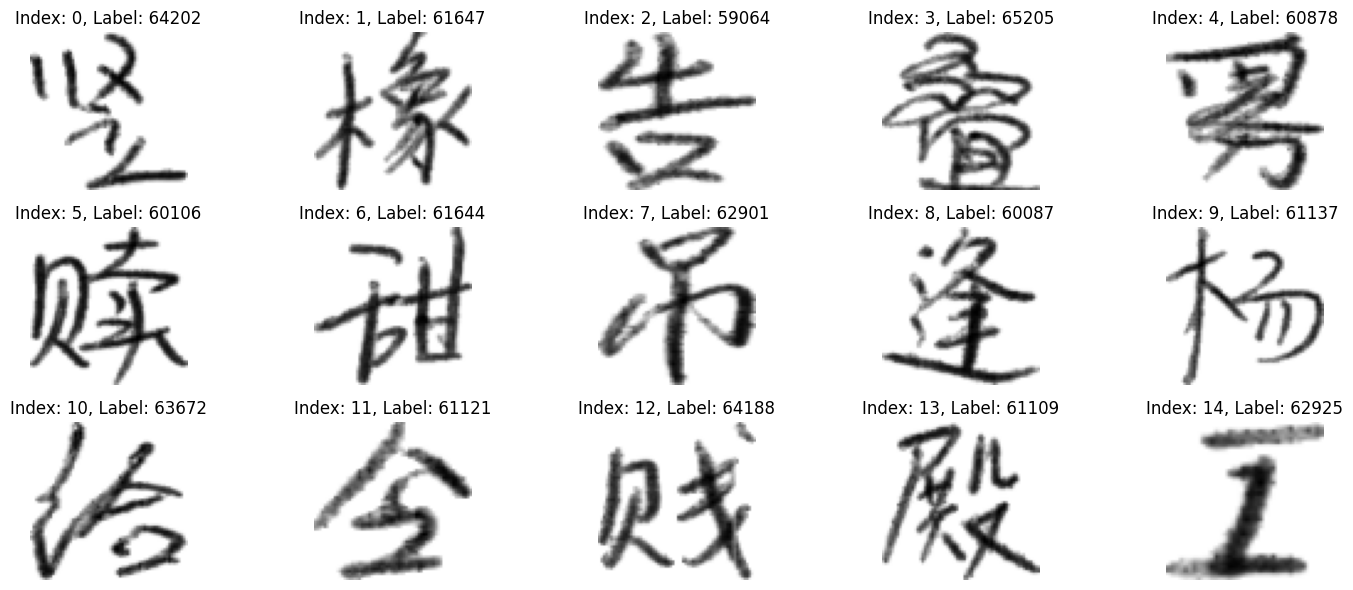

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(15, 6))
offset = 0
for idx, ax in enumerate(axes.flat):
    ax.imshow(images[offset + idx][0], cmap='gray')
    ax.axis("off")
    ax.set_title(f"Index: {offset + idx}, Label: {labels[offset + idx]}")
plt.tight_layout()
plt.show()